# Beijing PM2.5 Air-Pollution Prediction

Five years of hourly weather and pollution readings from the US Embassy in Beijing (2010–2014). Predict the **PM2.5 concentration** (the fine particles that make air dangerous) from the weather alone — dew point, temperature, pressure, wind and precipitation.


In [1]:
import io, urllib.request, zipfile
import numpy as np
import pandas as pd

def download(url):
    req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
    with urllib.request.urlopen(req, timeout=120) as r:
        return r.read()
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import r2_score, mean_absolute_error

raw = download('https://archive.ics.uci.edu/static/public/381/beijing+pm2+5+data.zip')
zf = zipfile.ZipFile(io.BytesIO(raw))
name = [n for n in zf.namelist() if n.endswith('.csv')][0]
df = pd.read_csv(io.BytesIO(zf.read(name))).dropna(subset=['pm2.5'])
print(df.shape)
df.head()

(41757, 13)


,No,year,month,day,hour,pm2.5,DEWP,TEMP,PRES,cbwd,Iws,Is,Ir
24,25,2010,1,2,0,129.0,-16,-4.0,1020.0,SE,1.79,0,0
25,26,2010,1,2,1,148.0,-15,-4.0,1020.0,SE,2.68,0,0
26,27,2010,1,2,2,159.0,-11,-5.0,1021.0,SE,3.57,0,0
27,28,2010,1,2,3,181.0,-7,-5.0,1022.0,SE,5.36,1,0
28,29,2010,1,2,4,138.0,-7,-5.0,1022.0,SE,6.25,2,0


In [2]:
X = pd.get_dummies(df[['year', 'month', 'day', 'hour', 'DEWP', 'TEMP', 'PRES', 'cbwd', 'Iws', 'Is', 'Ir']], columns=['cbwd'], drop_first=True)
y = df['pm2.5']
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, random_state=42)
rf = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1).fit(Xtr, ytr)
lin = make_pipeline(StandardScaler(), LinearRegression()).fit(Xtr, ytr)
import numpy as np
print(f'Always-average MAE: {np.mean(np.abs(yte - ytr.mean())):.1f}')
for name_m, m in [('Random Forest', rf), ('Linear', lin)]:
    p = m.predict(Xte)
    print(f'{name_m:15s} R2 {r2_score(yte, p):.3f}  MAE {mean_absolute_error(yte, p):.1f} ug/m3')

Always-average MAE: 68.8


Random Forest   R2 0.840  MAE 22.3 ug/m3
Linear          R2 0.273  MAE 56.8 ug/m3


DEWP     0.249669
day      0.149617
month    0.135686
TEMP     0.127455
PRES     0.092419
Iws      0.088572
year     0.063795
hour     0.051192
dtype: float64


<Axes: title={'center': 'What drives PM2.5?'}>

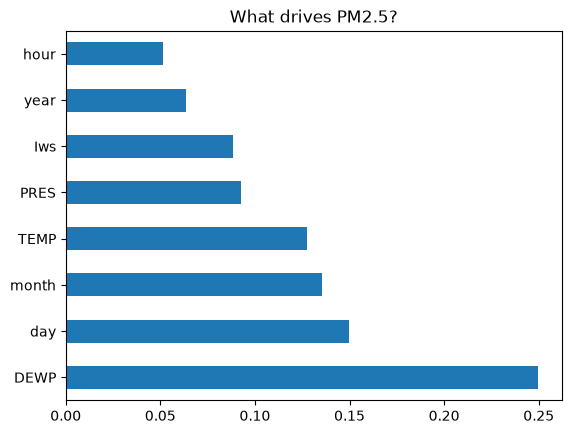

In [3]:
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
print(imp.head(8))
imp.head(8).plot(kind='barh', title='What drives PM2.5?')